# CMSE 201 Final Project

#### CMSE 201 Final Project
### &#9989; SOPHIE SCHERKENBACH
### &#9989; Section_006
#### &#9989; Dec 1, 2025

# ___STUDENTS AND SOCIAL MEDIA USAGE___

## Background and Motivation


I want to know how social media affects the lives of students in terms of mental health, etc. This data set measures that as well as accounts for gender, country, and education level. It has data on the most used platforms, hours per day spent on social media, and defines an “addiction score” from 1 to 10 showing how reliant a student is on social media to sustain them during the day. That scale is based on the “Bergan Social Media Addiction Scale” which uses a questionnaire about social media use and reliance in order to calculate the score. The website with information on this questionnaire interestingly says “N/A” under ethical considerations which is questionable.
        
In terms of the dataset, the population is 705, which seems high enough that the results won’t be too crazy, but definitely not high enough to make any conclusions about the entire student population. Participants were recruited through surveys on social media and through email, which is good because sending them through email means that some of the respondents might not be on social media, which would provide a good control. It is mentioned in the Kaggle post that the limitations of this data set are that it is self-reported, which means students likely underexaggerated their social media use, and the fact that there was only digital means of reaching out to students means those that do not have the same access to internet, perhaps in other countries, are lacking from this data set. 

The main question I will be attempting to answer is: Does social media addiction correlate with students' mental health?


## Methodology

In [33]:
# importing all the necessary packages I will be using

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

In [3]:
# importing the file and checking to see that it loaded in properly

students = pd.read_csv('Students_Social_Media_Addiction.csv')
students.head()

,Student_ID,Age,Gender,Academic_Level,Country,Avg_Daily_Usage_Hours,Most_Used_Platform,Affects_Academic_Performance,Sleep_Hours_Per_Night,Mental_Health_Score,Relationship_Status,Conflicts_Over_Social_Media,Addicted_Score
0,1,19,Female,Undergraduate,Bangladesh,5.2,Instagram,Yes,6.5,6,In Relationship,3,8
1,2,22,Male,Graduate,India,2.1,Twitter,No,7.5,8,Single,0,3
2,3,20,Female,Undergraduate,USA,6.0,TikTok,Yes,5.0,5,Complicated,4,9
3,4,18,Male,High School,UK,3.0,YouTube,No,7.0,7,Single,1,4
4,5,21,Male,Graduate,Canada,4.5,Facebook,Yes,6.0,6,In Relationship,2,7


The first thing I will be doing to model the data is make a scatter plot and line of best fit for Mental Health Score vs. Addiction Score to see if there is a correlation

In [80]:
# First, I am defining a linear function to make a line of best fit

def linear_function(x, m, b):
    return m * x + b

In [81]:
# Doing my curve_fit work to get a slope and intercept

linear, covariance = curve_fit(linear_function, students["Addicted_Score"], students["Mental_Health_Score"])
m_fit, b_fit = linear
y_fitted = linear_function(students["Addicted_Score"], m_fit, b_fit)
x = students["Addicted_Score"]
y = students["Mental_Health_Score"]

In [82]:
# Printing the slope and y-intercept

print(m_fit)
print(b_fit)

-0.6579867167958556
10.46233151889304


In [83]:
# Finding the R^2 [R Squared] value of the function

ss_total = np.sum((y - np.mean(y))**2)
ss_residual = np.sum((y - y_fitted)**2)
r_squared = 1 - (ss_residual / ss_total)
print(r_squared)

0.8931207796934594


Text(0.5, 1.0, 'Mental Health Score vs Addiction Score')

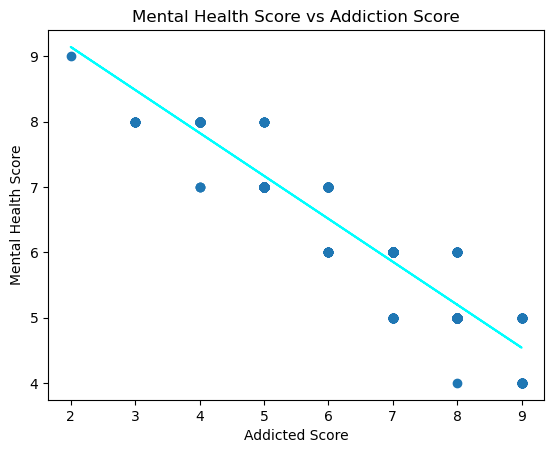

In [85]:
# Graphing the scatter plot and line of best fit

plt.scatter(x, y)
plt.plot(students["Addicted_Score"], y_fitted, color='aqua', label='Fitted Linear Model')
plt.xlabel("Addicted Score")
plt.ylabel("Mental Health Score")
plt.title("Mental Health Score vs Addiction Score")

Next, I make several heatmaps that compare Addicted Score, Mental Health Score, and various demographic factors. There is one heatmap for eveyr demographic factor I used.

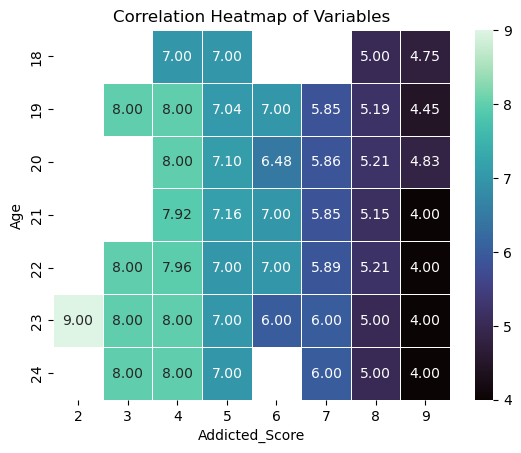

In [31]:
# Plotting heatmap that compares Addicted Score and Mental Health Score against age

student_heat = students.pivot_table(
    index="Age",
    columns="Addicted_Score",
    values="Mental_Health_Score",
    aggfunc="mean"
)
sns.heatmap(student_heat, annot=True, fmt=".2f", linewidths=.5, cmap="mako")
plt.title('Correlation Heatmap of Variables')
plt.show()

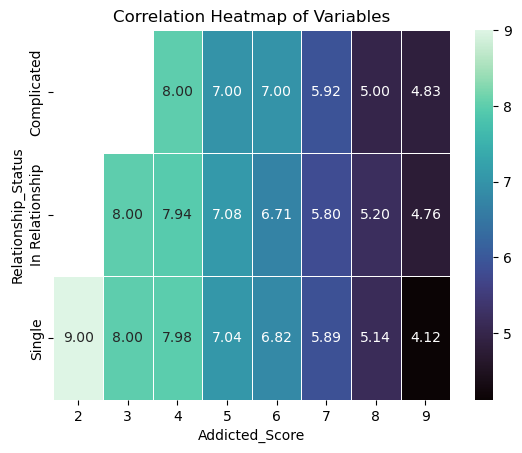

In [50]:
# Plotting heatmap that compares Addicted Score and Mental Health Score against relationship status.

student_heat = students.pivot_table(
    index="Relationship_Status",
    columns="Addicted_Score",
    values="Mental_Health_Score",
    aggfunc="mean"
)
sns.heatmap(student_heat, annot=True, fmt=".2f", linewidths=.5, cmap="mako")
plt.title('Correlation Heatmap of Variables')
plt.show()

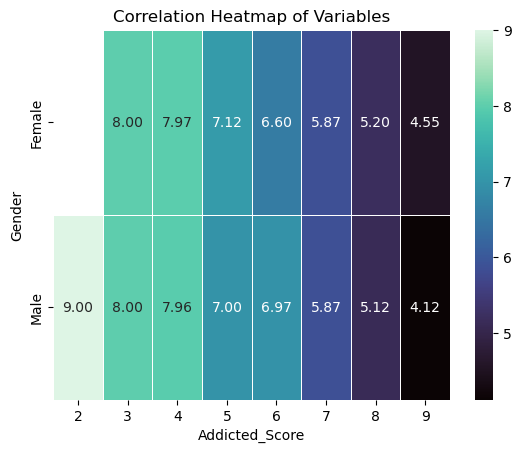

In [51]:
# Plotting heatmap that compares Addicted Score and Mental Health Score against gender.

student_heat = students.pivot_table(
    index="Gender",
    columns="Addicted_Score",
    values="Mental_Health_Score",
    aggfunc="mean"
)
sns.heatmap(student_heat, annot=True, fmt=".2f", linewidths=.5, cmap="mako")
plt.title('Correlation Heatmap of Variables')
plt.show()

C:\Users\sophi\AppData\Local\Temp\ipykernel_33220\1229855218.py:17: FutureWarning: The default value of observed=False is deprecated and will change to observed=True in a future version of pandas. Specify observed=False to silence this warning and retain the current behavior
  student_heat = students.pivot_table(


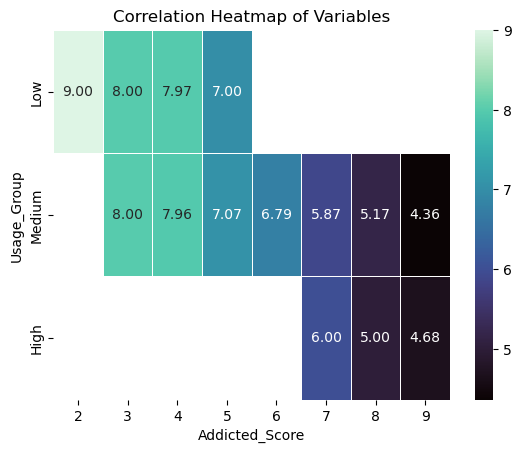

In [74]:
# Sorting Average Daily Usage Hours into 3 groups: low, medium, and high

group_list = []

for score in students["Avg_Daily_Usage_Hours"]:
    if score <= 3:
        group_list.append("Low")
    elif score <= 7:
        group_list.append("Medium")
    else:
        group_list.append("High")

students["Uasge_Group"] = group_list

low = students[students["Usage_Group"] == "Low"]["Mental_Health_Score"]
medium = students[students["Usage_Group"] == "Medium"]["Mental_Health_Score"]
high = students[students["Usage_Group"] == "High"]["Mental_Health_Score"]

# Plotting heatmap that compares Addicted Score and Mental Health Score against age.

student_heat = students.pivot_table(
    index="Usage_Group",
    columns="Addicted_Score",
    values="Mental_Health_Score",
    aggfunc="mean"
)
sns.heatmap(student_heat, annot=True, fmt=".2f", linewidths=.5, cmap="mako")
plt.title('Correlation Heatmap of Variables')
plt.show()


Next, I will do an ANOVA, or "Analysis of Variance" test to see if the relationship within groups of addictedness are more spread out than the relationship between different groups.

F-statistic: 415.9078079053237
p-value: 7.210227140291602e-120


C:\Users\sophi\AppData\Local\Temp\ipykernel_33220\3715676797.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Addiction_Group', y='Mental_Health_Score', data=students, order=["Low", "Medium", "High"], palette='mako')


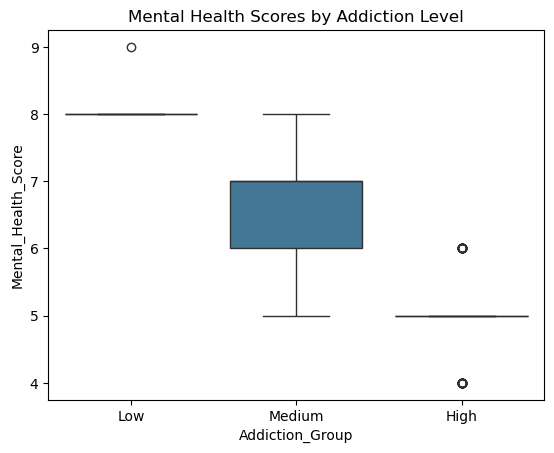

In [72]:
# Sorting Addicted Score into groups: low, medium, high

group_list = []

for score in students["Addicted_Score"]:
    if score <= 3:
        group_list.append("Low")
    elif score <= 7:
        group_list.append("Medium")
    else:
        group_list.append("High")

students["Addiction_Group"] = group_list

low = students[students["Addiction_Group"] == "Low"]["Mental_Health_Score"]
medium = students[students["Addiction_Group"] == "Medium"]["Mental_Health_Score"]
high = students[students["Addiction_Group"] == "High"]["Mental_Health_Score"]

# Computing the F statistic and p value and then printing

f_stat, p_val = stats.f_oneway(low, medium, high)

print("F-statistic:", f_stat)
print("p-value:", p_val)

# Visualizing the data using a boxplot

sns.boxplot(x='Addiction_Group', y='Mental_Health_Score', data=students, order=["Low", "Medium", "High"], palette='mako')
plt.title("Mental Health Scores by Addiction Level")
plt.show()

## Results

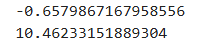

The equation for the lien of best fit for comparing Mental Health and Addiction scores is y = -0.65 * x + 10.46. This shows an inverse relationship between mental health and addition levels, that being as addiction levels rise, mental health declines. 

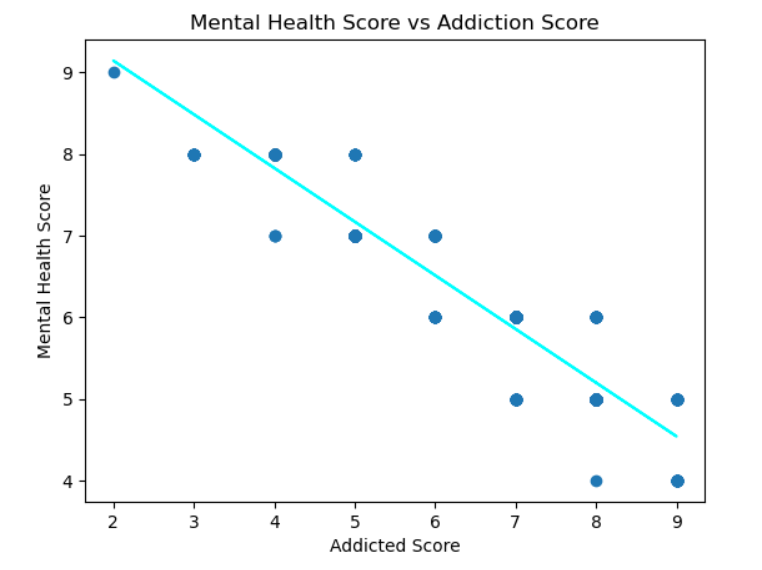

The graph confirms this negative relationship between mental health and addiction scores

The R-Squared value is 0.89, which means that 89% of the variation in mental health scores is accounted for by the variation in addiction scores

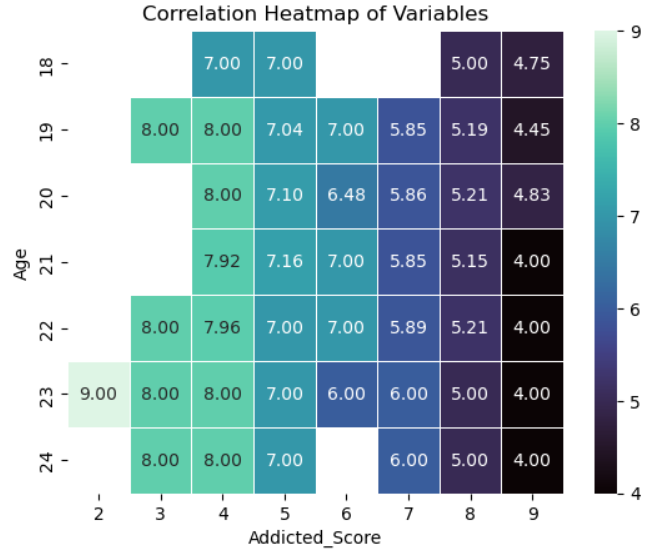
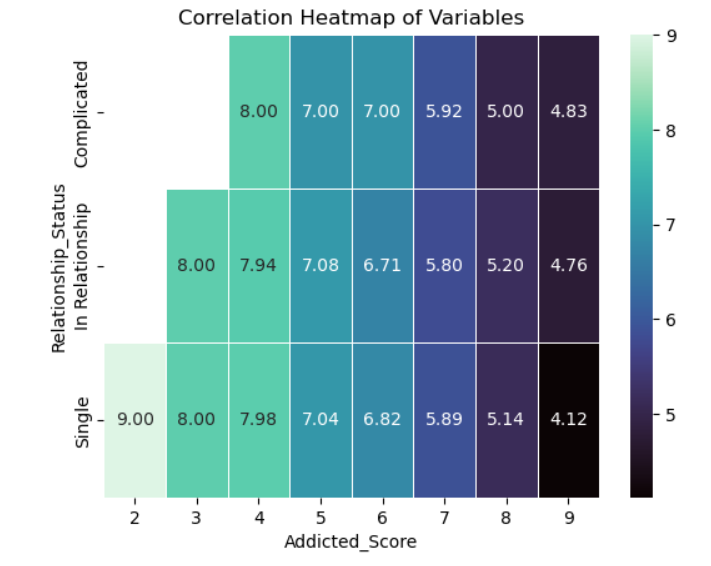 
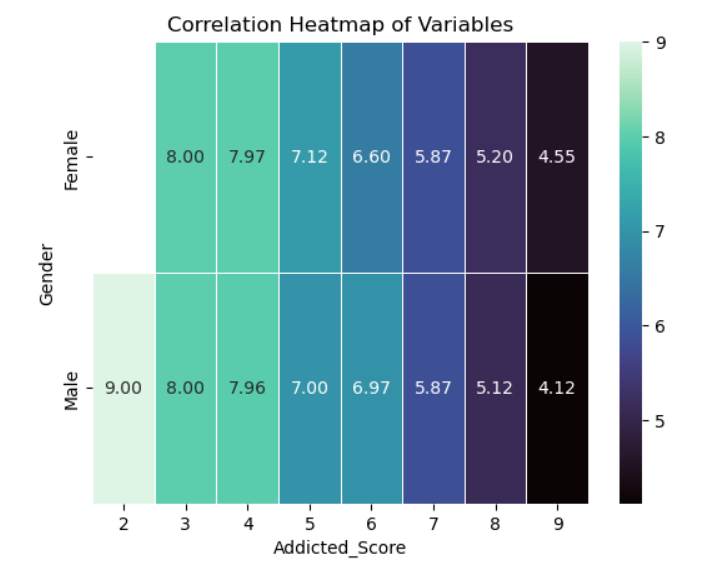
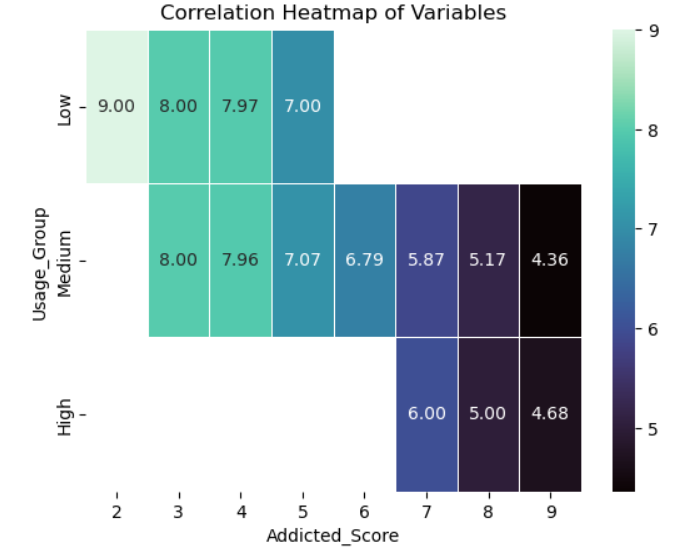

The heatmap further shows that higher addiction scores are correlated with lower mental health scores. This is true amongst all ages, genders, relationship statuses, and average usage hours surveyed

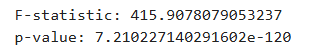

The high f statistic suggests that the variance between groups -- low, medium, and high addictedness -- is greater than the variance within groups. This further shows how addicted score and mental health score are correlated. The small p-value also proves its statistical significance.

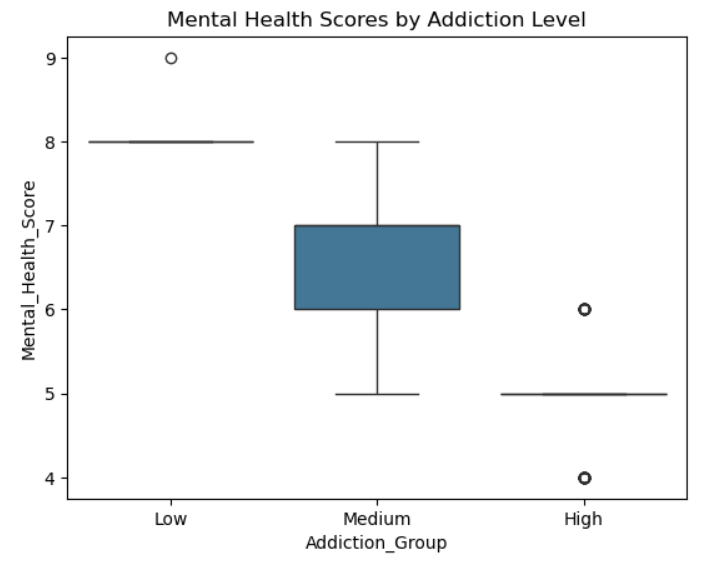

The boxplots show that the mean mental health score for high addictedness is much higher than that for low. The boxplots also match the downward trend seen in the original scatterplot. 

## Discussion and Conclusion

From the results, it is safe to say that mental health has a strong, negative correlation with social media addiction. As social media addiction increases, mental health decreases. The results showed that for every increase by 1 on the addiction scale, the mental health score dropped by 0.65. The results also showed that 89% of the variability in mental health was explained by the addicted score. All in all, students shoudl spend less time on social media and should see improved mental health outcomes if they do. 

While making the visualizations for the project, I noticed that there were not many data points. I figured out that this is because there are only 10 possible addiction and mental health scores, so all the points were concentrated together and it made 700+ points look like a dozen or so. Next time, I would try to find a data set that maybe measured things differently so that the visualizaitons turned out better. 

### References

Shamim, Adil. “Students’ Social Media Addiction.” Kaggle, 10 May 2025, www.kaggle.com/datasets/adilshamim8/social-media-addiction-vs-relationships. 

Paigemetcalfe. “Bergen Social Media Addiction Scale.” Salford PsyTech Home →⌂, 16 Feb. 2023, hub.salford.ac.uk/psytech/2021/08/10/bergen-social-media-addiction-scale/. 

“F_oneway#.” F_oneway - SciPy v1.16.2 Manual, docs.scipy.org/doc/scipy/reference/generated/scipy.stats.f_oneway.html. Accessed 23 Nov. 2025. 